In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import scipy as sc
from matplotlib.colors import LogNorm
from MKR_iterative import *

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern']})
plt.rcParams.update({'font.size': 10})
np.set_printoptions(linewidth=np.inf) #print in one row

# inicializacija

In [2]:
r=1 #polmer cevi - x
L=1 #dolžina cevi - y
Nx=1 + 50 #št. točk = št. delitev +1!
Ny=1 + 50
#Ny = Nx//2
dx=L/(Nx-1)
dy=r/(Ny-1)
print('št. računskih točk:',(Nx)*(Ny))

#diskretizacija
pointsall=np.zeros(((Nx)*(Ny),2))
for j in range(Ny):
    for i in range(Nx):
        index = (j)*(Nx)+i
        pointsall[index] = [i*dx, j*dy]
Nx,Ny,dx,dy

št. računskih točk: 2601


(51, 51, 0.02, 0.02)

In [3]:
# DE, RP
A = np.zeros(((Nx)*(Ny), (Nx)*(Ny)))
b = np.zeros(((Nx)*Ny))

# DE
for j in range(1,Ny-1):
    for i in range(1,Nx-1):
        ij_index = j*(Nx) + i #- Nx-1
        ij = 2*(1/dx**2 + 1/dy**2)
        ij_dx = -1/dx**2 - 1/(2*i*dx**2) #polarni dodatek!
        ij_dy = -1/dy**2

        #center
        A[ij_index, ij_index] += ij
        # okolica
        A[ij_index, ij_index-1] += ij_dx #levo
        A[ij_index, ij_index+1] += ij_dx #desno
        A[ij_index, ij_index-Nx] += ij_dy #dol
        A[ij_index, ij_index+Nx] += ij_dy #gor
        
        b[ij_index] = 0 #ni izvirov

# RP Dirichlet
T_rp1 = 0
T_rp2 = 1
for i in range(Nx):
    #spodaj
    #A[i, i] = 1
    #b[i] = T_rp1
    #zgoraj
    A[-Nx+i, -Nx+i] = 1
    b[-Nx+i] = T_rp1
for j in range(Ny):
    #levo
    #A[j*Nx, j*Nx] = 1
    #desno
    A[j*Nx+Nx-1, j*Nx+Nx-1] = 1
    if j*dy < r/2: #spodaj
        #b[j*Nx] = T_rp1 #L
        b[j*Nx+Nx-1] = T_rp1 #R
    else: #zgoraj
        #b[j*Nx] = T_rp2 #L
        b[j*Nx+Nx-1] = T_rp2 #R
# Neumann RP
for i in range(Nx): #spodaj
    #A[i, i] = 1/(2*dy) #centralna diferenčna shema okoli 1.vrste - vzame 0. in 2. vrsto
    #A[i, i+2*Nx] = -1/(2*dy)
    A[i, i] = 1/(dy) #diferenčna shema naprej okoli 0.vrste - vzame 0. in 1. vrsto
    A[i, i+Nx] = -1/(dy)
    b[i] = 2 #+tok noter, -ven
for j in range(1,Ny): #levo SYM RP - izolirano
    #A[j*Nx, j*Nx] = 1/(2*dx) #centralna diferenčna shema okoli 1.solpca - vzame 0. in 2. stolpec
    #A[j*Nx, j*Nx+2] = -1/(2*dx)
    A[j*Nx, j*Nx] = 1/(dx) #diferenčna shema naprej okoli 0.stolpca - vzame 0. in 1. stolpec
    A[j*Nx, j*Nx+1] = -1/(dx)
    b[j*Nx] = 0
# for j in range(Ny//2,Ny): #desno zgoraj toplotno izolirano, NAMESTO T_rp2
#     #A[j*Nx+Nx-1, j*Nx+Nx-2] = 1/(2*dy) #centralna diferenčna shema okoli zadnjga stolpca - vzame -1. in -3. stolpec
#     #A[j*Nx+Nx-1, j*Nx+Nx-1] = -1/(2*dy)
#     A[j*Nx+Nx-1, j*Nx+Nx-2] = -1/(dy) #diferenčna shema nazaj okoli zadnjega stolpca - vzame -1. in -2. stolpec
#     A[j*Nx+Nx-1, j*Nx+Nx-1] = 1/(dy)
#     b[j*Nx+Nx-1] = 0

In [ ]:
# def jacobi(A,q,N=1):
#     D = np.diag(A)
#     D_matrix = np.diagflat(D)
#     B = np.linalg.inv(D_matrix)
#     R = A - D_matrix
#     u = np.zeros_like(q)
#     u_n = np.zeros_like(u)

#     #iteracije
#     for n in range(N):
#         u_n = np.zeros_like(u)
#         # Dirichlet RP
#         for i in range(Nx): #gor
#             u_n[-Nx+i] = q[-Nx+i]
#         for j in range(Ny//2): #desno dol
#             u_n[j*Nx+Nx-1] = q[j*Nx+Nx-1]
#         for j in range(Ny//2,Ny-1): #desno gor
#             u_n[j*Nx+Nx-1] = q[j*Nx+Nx-1]
#         # Neumann RP
#         for i in range(Nx): #spodaj
#             u_n[i] = q[i]*dy + u[i+Nx]
#         for j in range(1,Ny): #levo
#             u_n[j*Nx] = q[j*Nx]*dx + u[j*Nx+1]
#         # for j in range(Ny//2,Ny): #desno zgoraj
#         #     u_n[j*Nx+Nx-1] = q[j*Nx+Nx-1]*dx + u[j*Nx+Nx-2]
        
#         for j in range(1,Ny-1):
#             for i in range(1,Nx-1):
#                 ij_index = j*Nx + i
#                 u_n[ij_index] = (q[ij_index] + 1/dx**2*(u[ij_index+1] + u[ij_index-1]) +
#                                                1/dy**2*(u[ij_index+Nx] + u[ij_index-Nx])) / D[ij_index]
#         #u_n = np.dot(B, q-R@u) #matrično, hitreje za male Nx,Ny
#         u = u_n
#     return u
# def gauss_seidel(A,q,N=1):
#     D = np.diag(A)
#     u = np.zeros_like(q)
#     u_n = np.zeros_like(u)

#     #iteracije
#     for n in range(N):
#         u_n = np.zeros_like(u)
#         # Dirichlet RP
#         for i in range(Nx): #gor
#             u_n[-Nx+i] = q[-Nx+i]
#         for j in range(Ny//2): #desno dol
#             u_n[j*Nx+Nx-1] = q[j*Nx+Nx-1]
#         for j in range(Ny//2,Ny-1): #desno gor
#             u_n[j*Nx+Nx-1] = q[j*Nx+Nx-1]
#         # Neumann RP
#         for i in range(Nx): #spodaj
#             u_n[i] = q[i]*dy + u[i+Nx]
#         for j in range(1,Ny): #levo
#             u_n[j*Nx] = q[j*Nx]*dx + u[j*Nx+1]
#         # for j in range(Ny//2,Ny): #desno zgoraj
#         #     u_n[j*Nx+Nx-1] = q[j*Nx+Nx-1]*dx + u[j*Nx+Nx-2]
#         for j in range(1,Ny-1):
#             for i in range(1,Nx-1):
#                 ij_index = j*Nx + i
#                 u_n[ij_index] = 1/D[ij_index] * (q[ij_index] + 1/dx**2*(u[ij_index+1] + u_n[ij_index-1]) 
#                                                              + 1/dy**2*(u[ij_index+Nx] + u_n[ij_index-Nx]))
#         u = u_n
#         #print(u)
#     return u
# def SOR(A,q,omega,N=1):
#     D = np.diag(A)
#     u_n = np.zeros_like(q)
#     u = np.copy(u_n)

#     #iteracije
#     for n in range(N):
#         #print(f'{n+1}/{N}',end='\r')
#         # Dirichlet RP
#         for i in range(Nx): #gor
#             u_n[-Nx+i] = q[-Nx+i]
#         for j in range(Ny//2): #desno dol
#             u_n[j*Nx+Nx-1] = q[j*Nx+Nx-1]
#         for j in range(Ny//2,Ny-1): #desno gor
#             u_n[j*Nx+Nx-1] = q[j*Nx+Nx-1]
#         # Neumann RP
#         for i in range(Nx): #spodaj
#             u_n[i] = q[i]*dy + u[i+Nx]
#         for j in range(1,Ny): #levo
#             u_n[j*Nx] = q[j*Nx]*dx + u[j*Nx+1]
#         # for j in range(Ny//2,Ny): #desno zgoraj
#         #     u_n[j*Nx+Nx-1] = q[j*Nx+Nx-1]*dx + u[j*Nx+Nx-2]
#         u_n = SOR_i(D,q,omega,u_n)
#         u=np.copy(u_n)
#         #print(u)
#     return u
# def jac_i(D,q,u):
#     u_n = np.copy(u)
#     for j in range(1,Ny-1):
#         for i in range(1,Nx-1):
#             ij_index = j*Nx + i
#             u_n[ij_index] = (q[ij_index] + 1/dx**2*(u[ij_index+1] + u[ij_index-1]) + 
#                            1/dy**2*(u[ij_index+Nx] + u[ij_index-Nx])) / D[ij_index]
#     return u_n
# def GS_i(D,q,u):
#     u_n = np.copy(u)
#     for j in range(1,Ny-1):
#         for i in range(1,Nx-1):
#             ij_index = j*Nx + i
#             u_n[ij_index] = 1/D[ij_index] * (q[ij_index] + 1/dx**2*(u[ij_index+1] + u_n[ij_index-1]) 
#                                                          + 1/dy**2*(u[ij_index+Nx] + u_n[ij_index-Nx]))
#     return u_n
# def SOR_i(D,q,omega,u):
    for j in range(1,Ny-1):
        for i in range(1,Nx-1):
            ij_index = j*Nx + i
            #u_gs = GS_i(A,q,u)
            u_gs = 1/D[ij_index] * (q[ij_index] + 1/dx**2*(u[ij_index+1] + u[ij_index-1]) 
                                                + 1/dy**2*(u[ij_index+Nx] + u[ij_index-Nx]))
            u[ij_index] = u[ij_index] + omega*(u_gs - u[ij_index])
    return u

# iteracije

In [24]:
#izračunana optimalna omega pri mrežah!
omega_101 = 1.971414141414141
omega_51 = 2
omega_51_lu= 1.9879310344827585

1.8839490122246525


1549.4975864442333

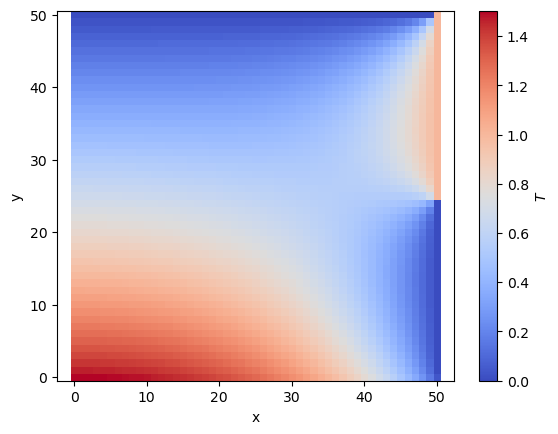

In [25]:
#referenca
omega = 2/(1+np.pi/Nx) #ocena
print(omega)
T_ref = SOR(A,b, omega ,N=1000)
res_ref= np.sum(np.abs(T_ref))

plt.imshow(T_ref.reshape((Nx,Ny)), cmap='coolwarm', origin='lower') #treba reshape!
plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.colorbar(label='$T$')
res_ref

In [26]:
N_max = 5e4
N0 = 1
D = np.diag(A)
N_list = np.arange(1,N_max,1, dtype=int)

N=N0
T_n = jacobi(A,b,N=N0)
residual = T_ref-T_n
residuali_j = []
while N < N_max:
    residual_old = np.copy(residual)
    T_old = np.copy(T_n)
    T_n = jac_i(D,b,T_old)
    residual = T_ref-T_n
    residuali_j.append(np.sum(np.abs(residual_old-residual)))
    N+=1
    print(f'{N}/{N_max}',end='\r')
    #if residual > residual_old: print('ne konvergira')
T_jac = T_n

In [8]:
N=N0
T_n = gauss_seidel(A,b,N=N0)
residual = T_ref-T_n
residuali_gs = []
while N < N_max:
    residual_old = np.copy(residual)
    T_old = np.copy(T_n)
    T_n = GS_i(D,b,T_old)
    residual = T_ref-T_n
    residuali_gs.append(np.sum(np.abs(residual_old-residual)))
    N+=1
    print(f'{N}/{N_max}',end='\r')
    #if residual > residual_old: print('ne konvergira')
T_gs = T_n

In [31]:
N_max = 5e3
N_list_sor = np.arange(1,N_max,1, dtype=int)
residuali_omega = []
omega = 2/(1+np.pi/Nx)
omega_list = np.linspace(omega-0.05, omega+0.05, 3)
omega_list = np.append(omega_list, omega_51_lu) #ocena od LU
omega_list = np.append(omega_list, omega_51) #ocena

for i in range(len(omega_list)):
    omega = omega_list[i]
    N=N0
    T_n = SOR(A,b,omega,N=N0)
    residual = T_ref-T_n
    residuali_sor = []
    while N < N_max:
        residual_old = np.copy(residual)
        T_old = np.copy(T_n)
        T_n = SOR_i(D,b,omega,T_old)
        residual = T_ref-T_n
        residuali_sor.append(np.sum(np.abs(residual_old-residual)))
        N+=1
        print(f'{N}/{N_max}',end='\r')
        #if residual > residual_old: print(f'ne konvergira: omega={omega:.3f}, N={N}',end='\r')
    print(f'\n{i+1}/{len(omega_list)}: omega={omega:.2f}, N={N}',end='\n')
    residuali_omega.append(residuali_sor)

5000/5000.0
1/5: omega=1.83, N=5000
5000/5000.0
2/5: omega=1.88, N=5000
5000/5000.0
3/5: omega=1.93, N=5000
5000/5000.0
4/5: omega=1.99, N=5000
5000/5000.0
5/5: omega=2.00, N=5000


In [32]:
omega = 2/(1+np.pi/Nx) #po enačbi
omega, omega_51, omega_51_lu

(1.8839490122246525, 2, 1.9879310344827585)

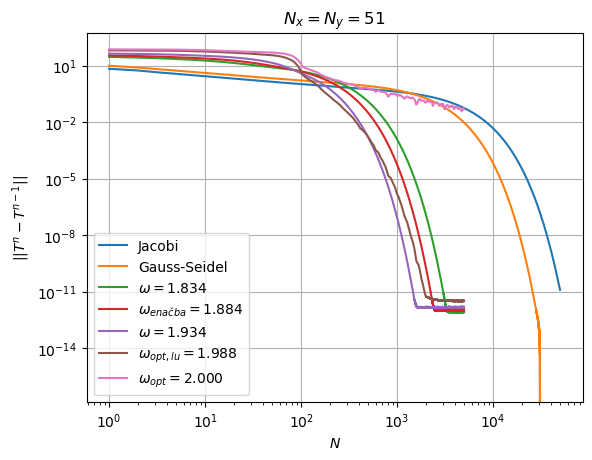

In [35]:
plt.plot(N_list,residuali_j,'-', label='Jacobi')
plt.plot(N_list,residuali_gs,'-', label='Gauss-Seidel')
for i in range(len(omega_list)):
    if omega_list[i] == 2/(1+np.pi/Nx): #po enačbi
        plt.plot(N_list_sor, residuali_omega[i],'-',label=f'$\omega_{{enačba}}=${omega_list[i]:.3f}')
    elif omega_list[i] == omega_51: #po enačbi
        plt.plot(N_list_sor, residuali_omega[i],'-',label=f'$\omega_{{opt}}=${omega_list[i]:.3f}')
    elif omega_list[i] == omega_51_lu: #po enačbi
        plt.plot(N_list_sor, residuali_omega[i],'-',label=f'$\omega_{{opt, lu}}=${omega_list[i]:.3f}')
    else:
        plt.plot(N_list_sor, residuali_omega[i],'-',label=f'$\omega=${omega_list[i]:.3f}')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('$N$')
plt.ylabel('$|| T^{n}-T^{n-1} ||$')
plt.legend()
plt.grid()
plt.title(f'$N_x=N_y=${Nx}')
# plt.savefig(f'slike/izboljsava_iteracije.pdf')